Pretrained vivit import

In [1]:
# torch 환경 세팅 버전(기록용)
# !pip install -U torch==2.3.1
# !pip install torchvision==0.17.2

## GPU 설정 단계

In [2]:
!nvidia-smi

Tue Apr  8 09:41:13 2025       
+-----------------------------------------------------------------------------+
| NVIDIA-SMI 525.105.17   Driver Version: 525.105.17   CUDA Version: 12.0     |
|-------------------------------+----------------------+----------------------+
| GPU  Name        Persistence-M| Bus-Id        Disp.A | Volatile Uncorr. ECC |
| Fan  Temp  Perf  Pwr:Usage/Cap|         Memory-Usage | GPU-Util  Compute M. |
|                               |                      |               MIG M. |
|===============================+======================+======================|
|   0  NVIDIA RTX A6000    On   | 00000000:1A:00.0 Off |                    0 |
| 30%   40C    P2    88W / 300W |   6527MiB / 46068MiB |      0%      Default |
|                               |                      |                  N/A |
+-------------------------------+----------------------+----------------------+
|   1  NVIDIA RTX A6000    On   | 00000000:1B:00.0 Off |                    0 |
| 38%   

In [3]:
import torch
import os
# print(torch.cuda. is_available())|

os.environ["CUDA_DEVICE_ORDER"]="PCI_BUS_ID"
os.environ["CUDA_VISIBLE_DEVICES"]= "0,1"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [4]:
print('Device:', device)  # 출력결과: cuda 
print('Count of using GPUs:', torch.cuda.device_count())  
print('Current cuda device:', torch.cuda.current_device()) 

Device: cuda
Count of using GPUs: 2
Current cuda device: 0


In [5]:
from transformers import VideoMAEModel
import torch

model = VideoMAEModel.from_pretrained("MCG-NJU/videomae-base")

In [6]:
from transformers import VideoMAEConfig, VideoMAEModel

# Initializing a VideoMAE videomae-base style configuration
configuration = VideoMAEConfig()

# Accessing the model configuration
configuration = model.config

## Data input 수정 코드
- 입력 데이터 준비 및 모델 예측 실행
- 데이터 전처리 파트
- PyAV decoder를 사용해서 영상 디코딩

### 수정한 내용들
- 여러 데이터를 넣을 수 있게 진행
- def문은 유지
- for 말고 map 함수 쓰는 게 효율이 높아 보임

In [7]:
import av
import os
import numpy as np
from transformers import AutoImageProcessor, VideoMAEForPreTraining

np.random.seed(0)
image_processor = AutoImageProcessor.from_pretrained("MCG-NJU/videomae-base")

def read_video_pyav(container, indices):
    '''
    Decode the video with PyAV decoder.
    Args:
        container (`av.container.input.InputContainer`): PyAV container.
        indices (`List[int]`): List of frame indices to decode.
    Returns:
        result (np.ndarray): np array of decoded frames of shape (num_frames, height, width, 3).
    '''
    frames = []
    container.seek(0)
    start_index = indices[0]
    end_index = indices[-1]
    for i, frame in enumerate(container.decode(video=0)):
        if i > end_index:
            break
        if i >= start_index and i in indices:
            frames.append(frame)
    return np.stack([x.to_ndarray(format="rgb24") for x in frames])


def sample_frame_indices(clip_len, frame_sample_rate, seg_len):
    '''
    Sample a given number of frame indices from the video.
    Args:
        clip_len (`int`): Total number of frames to sample.
        frame_sample_rate (`int`): Sample every n-th frame.
        seg_len (`int`): Maximum allowed index of sample's last frame.
    Returns:
        indices (`List[int]`): List of sampled frame indices
    '''
    converted_len = int(clip_len * frame_sample_rate)
    
    if seg_len == 0:
        raise ValueError("ERROR: 비디오의 총 프레임 수가 0입니다. 해당 비디오는 처리 불가")
    
    # seg_len이 너무 작을 경우 방지
    if seg_len < converted_len:
        # print(f"ERROR: `seg_len`({seg_len})이 `converted_len`({converted_len})보다 작아서 샘플링 불가")
        converted_len = seg_len
    
    # 샘플링할 프레임 범위 조정
    end_idx = np.random.randint(converted_len, seg_len) if seg_len > converted_len else seg_len
    start_idx = max(0, end_idx - converted_len)  # 음수가 되지 않도록 조정

    indices = np.linspace(start_idx, end_idx, num=clip_len)
    indices = np.clip(indices, start_idx, end_idx - 1).astype(np.int64)
    
    return indices

def process_video(video_file):
    container = av.open(video_file)
    
    # 비디오의 총 프레임 개수 가져오기
    total_frames = container.streams.video[0].frames
    if total_frames == 0:
        raise ValueError(f"ERROR: 비디오 {video_file}의 총 프레임 수가 0이므로 처리 불가")

    indices = sample_frame_indices(clip_len=16, frame_sample_rate=1, seg_len=total_frames)
    video = read_video_pyav(container=container, indices=indices)
    inputs = image_processor(list(video), return_tensors="pt")
    
    # inputs["pixel_values"] = inputs["pixel_values"].to(torch.float16).to(device)
    
    return inputs["pixel_values"] # 다른 모델들과 다르게, 픽셀 값으로 반환 # 기존 코드가 그래서 동일하게 변형함

# 비디오 파일이 저장된 디렉토리 경로
# video_folder_path = "/Data3/hj24/CCTV/DATA/video_data/train"
video_folder_path = "/Data3/hj24/CCTV/DATA/crashdata"
video_files = [os.path.join(video_folder_path, filename) for filename in os.listdir(video_folder_path) if filename.endswith(".mp4")]

# map()을 사용하여 모든 비디오 파일을 처리
# results = map(process_video, video_files)

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.48, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


## Video classification
- json file을 사용해 label을 설정하려 했지만 실패
- data folder를 accident, non-accident로 분류해 label를 추가

In [8]:
import av
import numpy as np
import torch
import os
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from transformers import AutoImageProcessor, VideoMAEForVideoClassification

np.random.seed(0)
torch.manual_seed(0)

# 데이터셋 클래스 정의
class VideoDataset(Dataset):
    def __init__(self, video_files, labels, image_processor):
        self.video_files = video_files
        self.labels = labels
        self.image_processor = image_processor

    def __len__(self):
        return len(self.video_files)

    def __getitem__(self, idx):
        container = av.open(self.video_files[idx])
        total_frames = container.streams.video[0].frames
        
        if total_frames == 0:
            raise ValueError(f"ERROR: 비디오 {self.video_files[idx]}의 프레임 수가 0")

        indices = sample_frame_indices(clip_len=16, frame_sample_rate=4, seg_len=total_frames)
        video = read_video_pyav(container, indices)
        inputs = self.image_processor(list(video), return_tensors="pt")
        
        return inputs["pixel_values"].squeeze(0), torch.tensor(self.labels[idx], dtype=torch.long)


# 데이터 분류
# accident, non-accident label 생성을 위해 데이터 폴더 분리 + 이걸 이용해 레이블 생성성
# video_folder_path = "/Data3/hj24/CCTV/DATA/video_data/train"
video_folder_path = "/Data3/hj24/CCTV/DATA/crashdata"
video_files = []
labels = []

accident_folder = os.path.join(video_folder_path, "accident")
if os.path.exists(accident_folder):
    for filename in os.listdir(accident_folder):
        if filename.endswith(".mp4"):
            video_files.append(os.path.join(accident_folder, filename))
            labels.append(1) 

non_accident_folder = os.path.join(video_folder_path, "non-accident")
if os.path.exists(non_accident_folder): 
    for filename in os.listdir(non_accident_folder):
        if filename.endswith(".mp4"):
            video_files.append(os.path.join(non_accident_folder, filename))
            labels.append(0) 

print(f"총 {len(video_files)}개의 비디오 파일이 로드됨.")
print(f"레이블 개수: {len(labels)}")
assert len(video_files) == len(labels), "❌ 데이터와 레이블 개수가 일치하지 않습니다!"

총 4500개의 비디오 파일이 로드됨.
레이블 개수: 4500


In [9]:
import torch
import av
import numpy as np
import torch
import os
import torch.nn as nn
import torch.nn.init as init
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, random_split
from torchmetrics.classification import Accuracy
from peft import LoraConfig, get_peft_model

class VideoClassifier(nn.Module):
    def __init__(self, base_model):
        super(VideoClassifier, self).__init__()
        self.videomae = base_model
        self.classifier = nn.Linear(self.videomae.config.hidden_size, 2)  # 2개의 클래스 (accident, non-accident)

    def forward(self, x):
        outputs = self.videomae(x, output_hidden_states=True)  # 숨겨진 상태 반환
        features = outputs.hidden_states[-1][:, 0, :]  # 마지막 hidden state의 [CLS] 토큰
        return self.classifier(features)
    
def initialize_classifier_weights(model):
    """분류 부분 가중치 초기화 코드"""
    for m in model.modules():
        if isinstance(m, nn.Linear):
            init.xavier_uniform_(m.weight)
            if m.bias is not None:
                init.zeros_(m.bias)

lora_config = LoraConfig(
    r=8,  # LoRA 랭크
    lora_alpha=16,  # 스케일링 파라미터 # r*2
    target_modules=["attention.output.dense"],  # 타겟 모듈 # 늘릴 수 있음
    lora_dropout=0.1
)

model = get_peft_model(model, lora_config)
model = VideoClassifier(model)
model.apply(initialize_classifier_weights)
model = nn.DataParallel(model).to(device)

# 데이터로더 생성
dataset = VideoDataset(video_files, labels, image_processor)
generator = torch.Generator().manual_seed(torch.initial_seed()) # 랜덤하게 데이터 섞기

# 분리
total_size = len(dataset)
train_size = int(0.7 * total_size)
val_size = int(0.2 * total_size)
test_size = total_size - train_size - val_size

train_dataset, val_dataset, test_dataset = random_split(dataset, [train_size, val_size, test_size], generator)
print(f"Train: {len(train_dataset)}, Validation: {len(val_dataset)}, Test: {len(test_dataset)}")

# DataLoader 설정 (매 에폭마다 데이터 순서를 랜덤하게)
train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=8, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=8, shuffle=False)

Train: 3150, Validation: 900, Test: 450


## 학습

In [ ]:
# 학습 설정
criterion = nn.CrossEntropyLoss()
trainable_params = list(model.module.videomae.parameters()) + list(model.module.classifier.parameters())
optimizer = optim.Adam(trainable_params, lr=1e-4)
accuracy_metric = Accuracy(task="multiclass", num_classes=2).to(device)

train_acc, val_acc, train_loss, val_loss = [], [], [], []

for epoch in range(50):
    model.train()
    accuracy_metric.reset()
    total_train_loss = 0
    
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        
        optimizer.zero_grad()
        logits = model(inputs)
        # logits = outputs.logits
        
        # logits = outputs
        loss = criterion(logits, labels)
        loss.backward()
        total_train_loss += loss.item()
        
        optimizer.step()
        
        preds = torch.argmax(logits, dim=1)
        accuracy_metric.update(preds, labels)
    
    epoch_accuracy = accuracy_metric.compute().item()
    avg_train_loss = total_train_loss/len(train_loader) 
    
    train_acc.append(epoch_accuracy)
    # train_loss.append(loss.item())
    train_loss.append(avg_train_loss)
    
    # 평가 모드
    model.eval() 
    accuracy_metric.reset()
    total_val_loss = 0
    
    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            logits = model(inputs)
            # logits = outputs.logits
            
            # logits = outputs
            loss = criterion(logits, labels)
            total_val_loss += loss.item()
            
            preds = torch.argmax(logits, dim=1)
            accuracy_metric.update(preds, labels)


    val_accuracy = accuracy_metric.compute().item()
    avg_val_loss = total_val_loss/len(val_loader)
    
    val_acc.append(val_accuracy)
    val_loss.append(avg_val_loss)
    # val_loss.append(loss.item())
    
    # print(f"Epoch {epoch+1}, Accuracy: {epoch_accuracy:.4f}, Validation Accuracy: {val_accuracy:.4f}")
    print(f"Epoch {epoch+1}, Loss: {train_loss[-1]:.4f}, Accuracy: {epoch_accuracy:.4f}, Validation Loss:{val_loss[-1]:.4f}, Validation Accuracy: {val_accuracy:.4f}")

torch.save(model.state_dict(), "videomae_accident_classifier.pth")

Epoch 1, Loss: 0.4246, Accuracy: 0.8311, Validation Loss:0.0027, Validation Accuracy: 0.8744
Epoch 2, Loss: 0.3192, Accuracy: 0.8806, Validation Loss:0.0021, Validation Accuracy: 0.9022
Epoch 3, Loss: 0.2550, Accuracy: 0.9083, Validation Loss:0.0013, Validation Accuracy: 0.9356
Epoch 4, Loss: 0.2298, Accuracy: 0.9117, Validation Loss:0.0013, Validation Accuracy: 0.9411
Epoch 5, Loss: 0.2002, Accuracy: 0.9283, Validation Loss:0.0011, Validation Accuracy: 0.9456
Epoch 6, Loss: 0.1910, Accuracy: 0.9292, Validation Loss:0.0018, Validation Accuracy: 0.9389
Epoch 7, Loss: 0.1815, Accuracy: 0.9346, Validation Loss:0.0012, Validation Accuracy: 0.9511
Epoch 8, Loss: 0.1764, Accuracy: 0.9324, Validation Loss:0.0012, Validation Accuracy: 0.9467
Epoch 9, Loss: 0.1727, Accuracy: 0.9362, Validation Loss:0.0015, Validation Accuracy: 0.9456
Epoch 10, Loss: 0.1646, Accuracy: 0.9429, Validation Loss:0.0011, Validation Accuracy: 0.9544
Epoch 11, Loss: 0.1544, Accuracy: 0.9489, Validation Loss:0.0009, Val

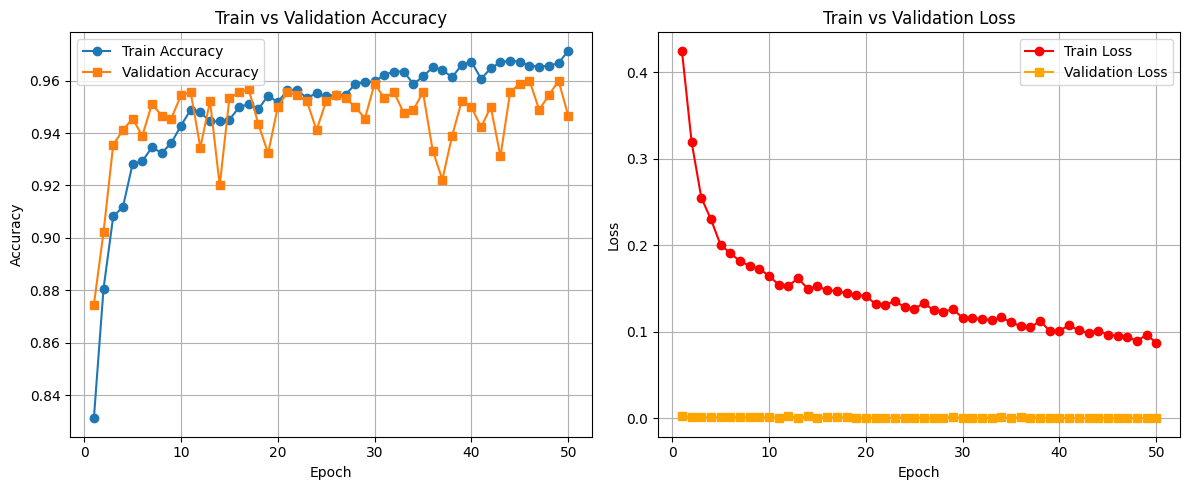

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# 🔹 Accuracy 그래프
plt.subplot(1, 2, 1)  # 1행 2열 중 첫 번째 그래프
plt.plot(range(1, 51), train_acc, label="Train Accuracy", marker="o")
plt.plot(range(1, 51), val_acc, label="Validation Accuracy", marker="s")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Train vs Validation Accuracy")
plt.legend()
plt.grid(True)

# 🔹 Loss 그래프
plt.subplot(1, 2, 2)  # 1행 2열 중 두 번째 그래프
plt.plot(range(1, 51), train_loss, label="Train Loss", marker="o", color="red")
plt.plot(range(1, 51), val_loss, label="Validation Loss", marker="s", color="orange")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Train vs Validation Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

## Test set으로 confusion matrix값

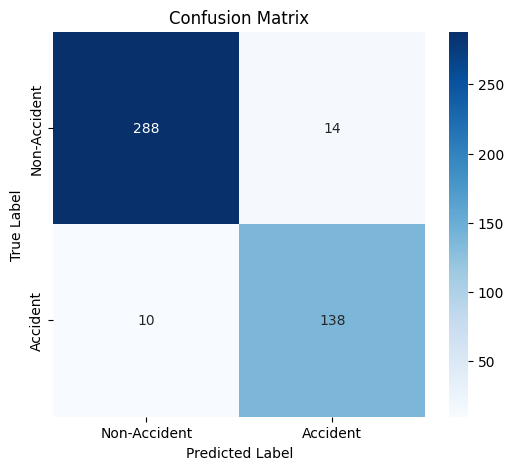

In [12]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# 테스트 예측값 저장
all_preds = []
all_labels = []

for inputs, labels in test_loader:
    inputs, labels = inputs.to(device), labels.to(device)

    with torch.no_grad():
        outputs = model(inputs)
        preds = torch.argmax(outputs, dim=1)

    all_preds.extend(preds.cpu().numpy())  # GPU에서 CPU로 이동 후 저장
    all_labels.extend(labels.cpu().numpy())

# Confusion Matrix 계산
cm = confusion_matrix(all_labels, all_preds)

# Confusion Matrix 시각화
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Non-Accident", "Accident"], yticklabels=["Non-Accident", "Accident"])
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.show()
